# EDA — Historial reciente de escucha (noviembre 2026)

**Universidad de Pamplona · Bases de Datos II**
**Integrantes:** Suley Suárez · Jhonatan Vera

Análisis de las reproducciones cargadas en el DWH compartido desde el despliegue.
Complementa a `eda_spotify_vera_suarez.ipynb` (mayo 2026), que se conserva sin cambios.

> No se consultan tokens, correos ni identificadores de Spotify. Las horas se muestran en hora de Colombia.

## 0. Configuración

In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import dotenv_values
from sqlalchemy import create_engine, text

warnings.filterwarnings("ignore")
engine = create_engine(dotenv_values("../backend/.env")["DATABASE_URL"])

ZONA = "America/Bogota"
USER_ID = 2                                    # usuario que se analiza en detalle
NOMBRES = {1: "Suley", 2: "Jhonatan"}
VERDE, MORADO = "#1DB954", "#8250ff"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

def read_sql(query, **params):
    with engine.connect() as conn:
        res = conn.execute(text(query), params)
        return pd.DataFrame(res.fetchall(), columns=list(res.keys()))

## 1. Datos disponibles y calidad

In [2]:
hist = read_sql('''
    SELECT h.user_id, h.played_at, h.context_type,
           t.track_id, t.name AS track, t.duration_ms, t.popularity,
           a.artist_id, a.name AS artist, a.genres, a.followers_count
    FROM dwh.fact_listening_history h
    JOIN dwh.dim_tracks t  ON t.track_id  = h.track_id
    JOIN dwh.dim_artists a ON a.artist_id = h.artist_id
''')
hist["local"] = pd.to_datetime(hist["played_at"]).dt.tz_localize("UTC").dt.tz_convert(ZONA)
hist["fecha"] = hist["local"].dt.date
hist["hora"] = hist["local"].dt.hour
hist["minutos"] = hist["duration_ms"] / 60000
mio = hist[hist["user_id"] == USER_ID].copy()
nombre = NOMBRES.get(USER_ID, f"Usuario {USER_ID}")

print(f"Rango de datos: {hist['local'].min():%d/%m %H:%M} a {hist['local'].max():%d/%m %H:%M} (hora de Colombia)")
print(f"Reproducciones totales: {len(hist)} | de {nombre}: {len(mio)} en {mio['fecha'].nunique()} día(s)")

Rango de datos: 25/11 00:06 a 25/11 22:53 (hora de Colombia)
Reproducciones totales: 133 | de Jhonatan: 50 en 1 día(s)


In [3]:
sin_genero = mio["genres"].apply(lambda g: not any(g or []))
calidad = pd.Series({
    "duración": mio["duration_ms"].isna().mean(),
    "popularidad de la canción": mio["popularity"].isna().mean(),
    "seguidores del artista": mio["followers_count"].isna().mean(),
    "género del artista": sin_genero.mean(),
    "contexto de reproducción": mio["context_type"].isin([None, "unknown"]).mean(),
}).mul(100).round(1)
display(calidad.to_frame("% sin dato"))
dup = hist.duplicated(["user_id", "played_at"]).sum()
print(f"Duplicados por (user_id, played_at): {dup}")

,% sin dato
duración,0.0
popularidad de la canción,100.0
seguidores del artista,0.0
género del artista,16.0
contexto de reproducción,2.0


Duplicados por (user_id, played_at): 0


## 2. ¿Cuándo escucho música?

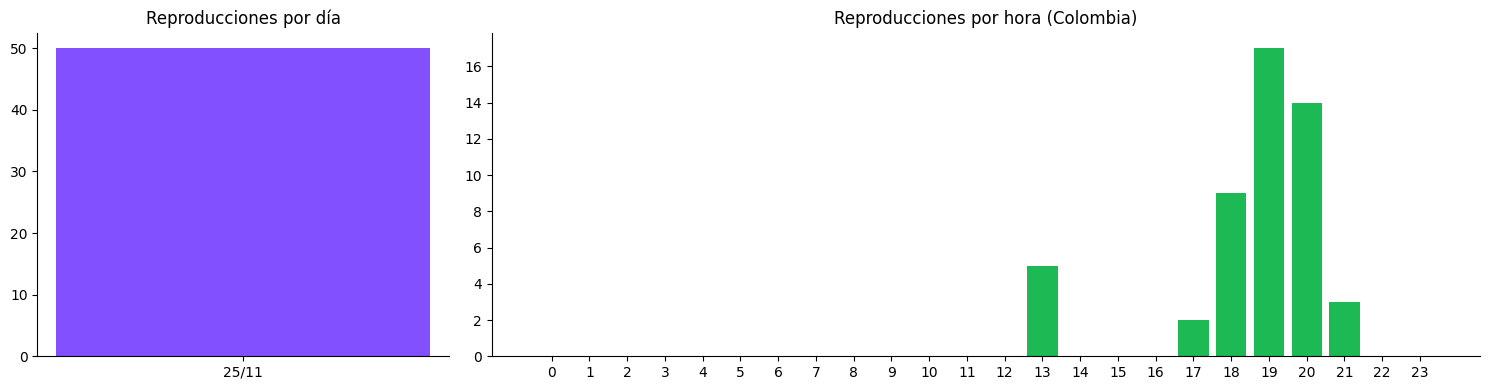

Hora pico: 19:00 con 17 reproducciones (34% del total).
Minutos estimados (duración completa de cada canción): 202


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2.4]})
por_dia = mio.groupby("fecha").size()
ax[0].bar([f"{d:%d/%m}" for d in por_dia.index], por_dia.values, color=MORADO)
ax[0].set_title("Reproducciones por día")
por_hora = mio.groupby("hora").size().reindex(range(24), fill_value=0)
ax[1].bar(por_hora.index, por_hora.values, color=VERDE)
ax[1].set_title("Reproducciones por hora (Colombia)")
ax[1].set_xticks(range(24))
plt.tight_layout(); plt.show()
print(f"Hora pico: {por_hora.idxmax():02d}:00 con {por_hora.max()} reproducciones "
      f"({por_hora.max() / len(mio):.0%} del total).")
print(f"Minutos estimados (duración completa de cada canción): {mio['minutos'].sum():.0f}")

## 3. Artistas y canciones más escuchados

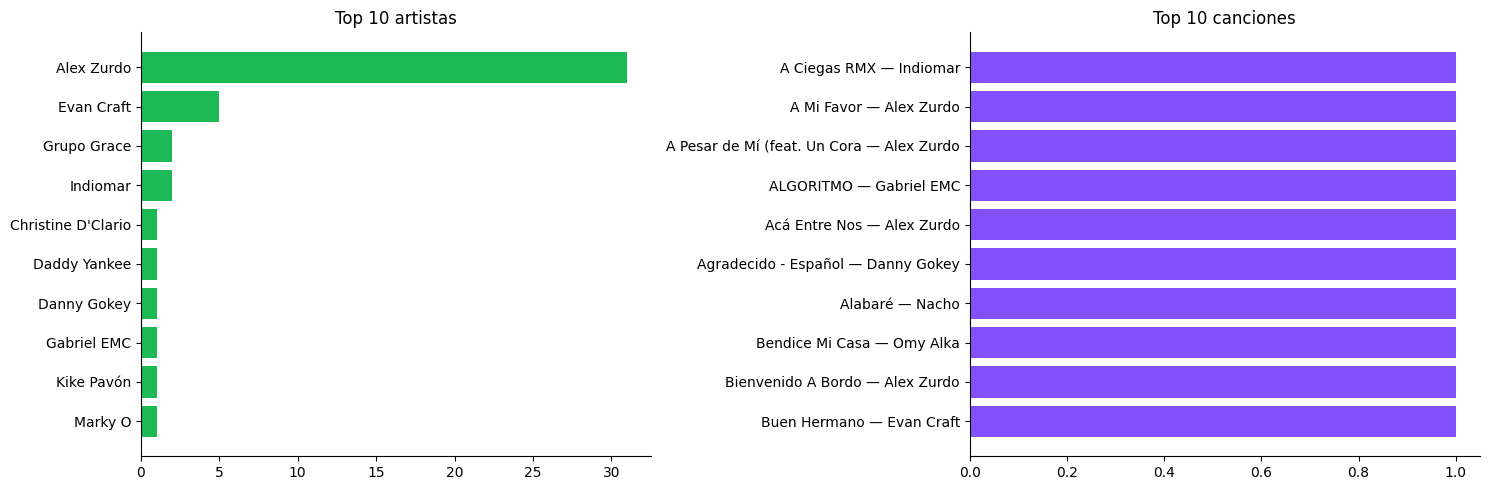

14 artistas y 50 canciones distintas.
Los 5 artistas principales suman el 82% de las reproducciones.
Reproducciones repetidas de una canción ya oída: 0.


In [5]:
top_a = mio.groupby("artist").size().nlargest(10)
top_t = mio.groupby(["track", "artist"]).size().nlargest(10)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(top_a.index[::-1], top_a.values[::-1], color=VERDE)
ax[0].set_title("Top 10 artistas")
ax[1].barh([f"{t[:28]} — {a[:18]}" for t, a in top_t.index][::-1], top_t.values[::-1], color=MORADO)
ax[1].set_title("Top 10 canciones")
plt.tight_layout(); plt.show()
print(f"{mio['artist_id'].nunique()} artistas y {mio['track_id'].nunique()} canciones distintas.")
print(f"Los 5 artistas principales suman el {top_a.head(5).sum() / len(mio):.0%} de las reproducciones.")
print(f"Reproducciones repetidas de una canción ya oída: {len(mio) - mio['track_id'].nunique()}.")

## 4. Géneros

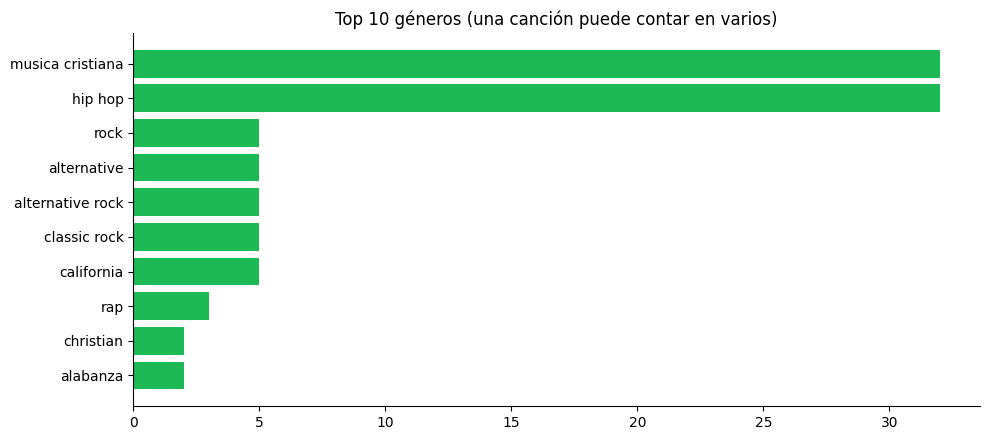

Género más frecuente: musica cristiana (27% de las etiquetas).


In [6]:
generos = mio["genres"].explode().dropna().astype(str).str.strip().str.lower()
generos = generos[generos != ""]
if generos.empty:
    print("No hay géneros registrados para estas reproducciones.")
else:
    top_g = generos.value_counts().head(10)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(top_g.index[::-1], top_g.values[::-1], color=VERDE)
    ax.set_title("Top 10 géneros (una canción puede contar en varios)")
    plt.tight_layout(); plt.show()
    print(f"Género más frecuente: {top_g.index[0]} ({top_g.iloc[0] / generos.size:.0%} de las etiquetas).")

## 5. Duración de las canciones

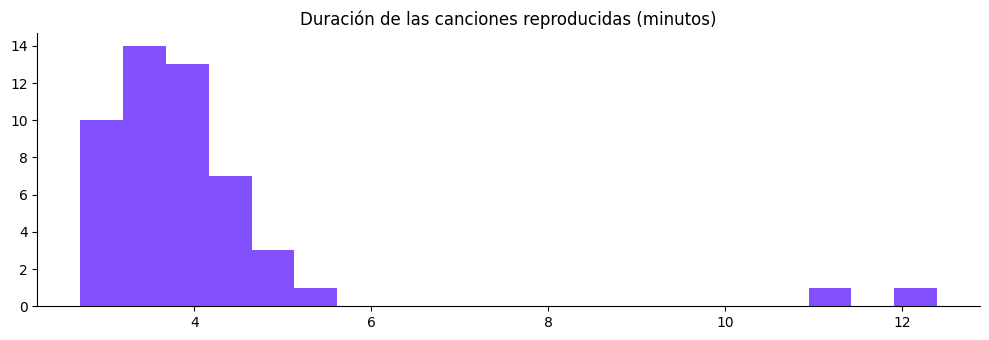

Media: 4.0 min | mediana: 3.7 min
En 150 minutos de escucha continua caben unas 37 canciones (Spotify entrega como máximo las últimas 50 por sincronización).


In [7]:
dur = mio["minutos"].dropna()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(dur, bins=20, color=MORADO)
ax.set_title("Duración de las canciones reproducidas (minutos)")
plt.tight_layout(); plt.show()
media = dur.mean()
print(f"Media: {media:.1f} min | mediana: {dur.median():.1f} min")
print(f"En 150 minutos de escucha continua caben unas {150 / media:.0f} canciones "
      "(Spotify entrega como máximo las últimas 50 por sincronización).")

## 6. Comparación entre las dos cuentas

In [8]:
comp = hist.groupby("user_id").agg(
    reproducciones=("track_id", "size"),
    canciones_distintas=("track_id", "nunique"),
    artistas_distintos=("artist_id", "nunique"),
    minutos_estimados=("minutos", "sum"),
).round(0).astype(int)
comp.index = [NOMBRES.get(i, f"Usuario {i}") for i in comp.index]
display(comp)
comunes = hist.groupby("artist_id")["user_id"].nunique().eq(2).sum()
print(f"Artistas escuchados por ambas cuentas: {comunes}")

,reproducciones,canciones_distintas,artistas_distintos,minutos_estimados
Suley,83,79,28,307
Jhonatan,50,50,14,202


Artistas escuchados por ambas cuentas: 0


## 7. Limitaciones

- La ventana de datos es de muy pocos días: los resultados describen ese periodo, no hábitos estables.
- Spotify solo entrega las últimas 50 reproducciones por consulta; lo escuchado entre sincronizaciones por encima de ese límite se pierde.
- Los minutos asumen que cada canción se escuchó completa.
- Los géneros provienen de etiquetas externas y pueden estar incompletos.

## 8. Conclusiones individuales

### Jhonatan Vera
_Pendiente de redactar._

### Suley Suárez
_Pendiente de redactar._